Всего календарных суток: 1442
Полных суток: 1358
Доступных измерений: 2049280
Измерений за полные сутки: 1955520


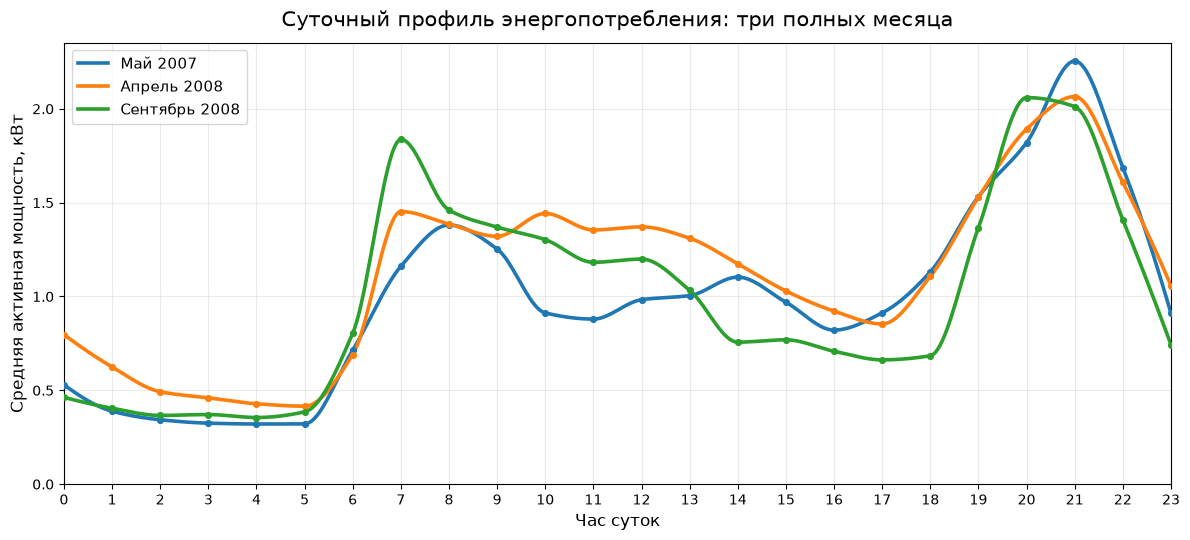

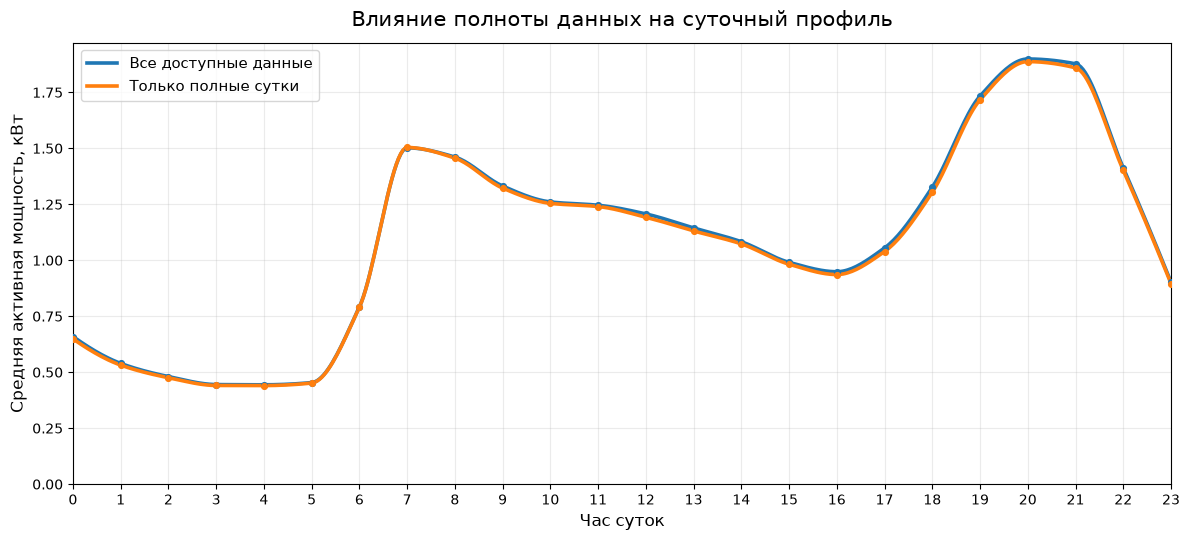

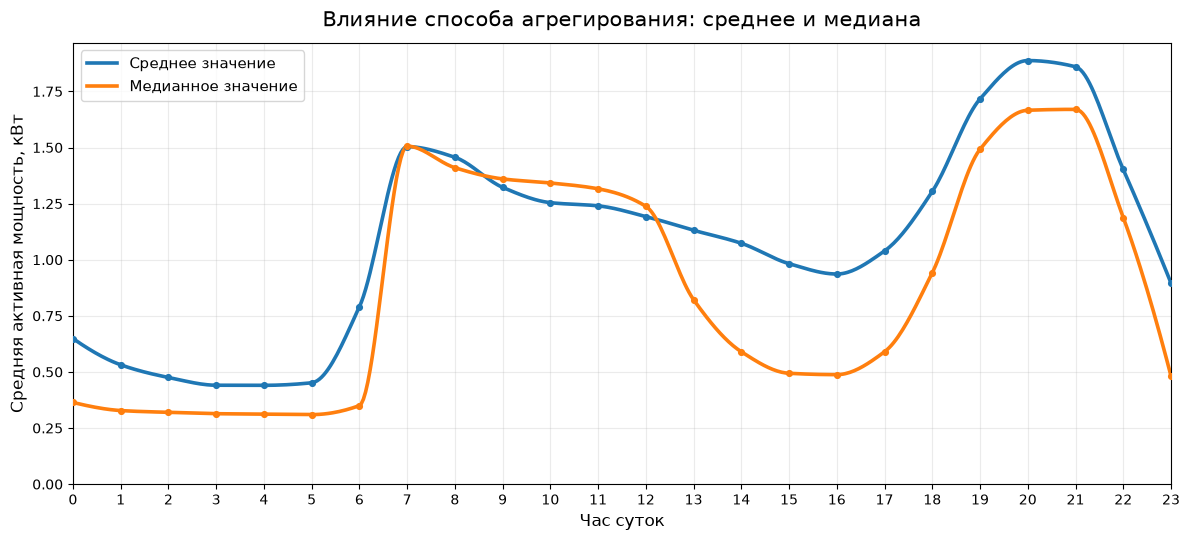


Численные характеристики суточных профилей:
      Профиль  Средняя мощность, кВт  Минимум, кВт  Час минимума  Максимум, кВт  Час максимума  Амплитуда, кВт
     Май 2007                  0.986         0.321             4          2.255             21           1.934
  Апрель 2008                  1.116         0.415             5          2.065             21           1.650
Сентябрь 2008                  0.988         0.355             4          2.060             20           1.705
   Все данные                  1.091         0.444             4          1.899             20           1.455
 Полные сутки                  1.082         0.440             4          1.887             20           1.447
      Среднее                  1.082         0.440             4          1.887             20           1.447
      Медиана                  0.871         0.310             5          1.670             21           1.360

Максимальное почасовое различие:
Все данные / полные сутки: 0.022 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from pathlib import Path

# ============================================================
# 1. ПОДГОТОВКА ДАННЫХ
# ============================================================

path = Path("/Users/danklo/Downloads/household_power_consumption.txt")
data = pd.read_csv(
    path,
    sep=";",
    header=0,
    keep_default_na=True,
    dtype={"Date": "string", "Time": "string"},
    low_memory=False,
    encoding="latin1",
    decimal="."
)

data["DateTime"] = pd.to_datetime(
    data["Date"] + " " + data["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

# Поддержка DateTime как столбца или индекса
if 'DateTime' not in data.columns:
    if isinstance(data.index, pd.DatetimeIndex):
        data = data.reset_index()
        data = data.rename(columns={data.columns[0]: 'DateTime'})
    else:
        raise ValueError("Не найден столбец или индекс DateTime")

data['DateTime'] = pd.to_datetime(
    data['DateTime'], errors='coerce'
)

data['Global_active_power'] = pd.to_numeric(
    data['Global_active_power'], errors='coerce'
)

data = data.dropna(subset=['DateTime']).copy()

# Проверка уникальности временных меток
if data['DateTime'].duplicated().any():
    raise ValueError(
        "Обнаружены повторяющиеся временные метки. "
        "Необходимо проверить дубликаты."
    )

data['date'] = data['DateTime'].dt.normalize()
data['hour'] = data['DateTime'].dt.hour
data['month'] = data['DateTime'].dt.to_period('M')

# Только реальные измерения, без заполнения пропусков
valid = data.dropna(
    subset=['Global_active_power']
).copy()

# Полные сутки = 1440 уникальных минут с измерениями
valid['minute'] = valid['DateTime'].dt.floor('min')

daily_counts = valid.groupby('date')['minute'].nunique()

full_dates = daily_counts[
    daily_counts == 1440
].index

full_days = valid[
    valid['date'].isin(full_dates)
].copy()

print("Всего календарных суток:", data['date'].nunique())
print("Полных суток:", len(full_dates))
print("Доступных измерений:", len(valid))
print("Измерений за полные сутки:", len(full_days))


# ============================================================
# 2. ФУНКЦИЯ ПОСТРОЕНИЯ ГЛАДКИХ ПРОФИЛЕЙ
# ============================================================

def plot_profiles(profiles, title, filename):

    fig, ax = plt.subplots(figsize=(12, 5.5))

    hours_smooth = np.linspace(0, 23, 500)

    for label, profile in profiles.items():

        # Профиль: Series с индексом 0...23
        profile = profile.reindex(range(24))

        # Не интерполируем отсутствующие почасовые значения
        if profile.isna().any():
            raise ValueError(
                f"В профиле '{label}' отсутствуют часы"
            )

        hours = profile.index.to_numpy(dtype=float)
        values = profile.to_numpy(dtype=float)

        # PCHIP используется только для визуализации
        smooth = PchipInterpolator(hours, values)
        line, = ax.plot(
            hours_smooth,
            smooth(hours_smooth),
            linewidth=2.6,
            label=label
        )

        # Реальные почасовые агрегаты
        ax.scatter(
            hours, values,
            color=line.get_color(),
            s=17,
            zorder=3
        )

    ax.set_title(title, fontsize=15, pad=12)
    ax.set_xlabel("Час суток", fontsize=12)
    ax.set_ylabel(
        "Средняя активная мощность, кВт",
        fontsize=12
    )

    ax.set_xticks(range(24))
    ax.set_xlim(0, 23)
    ax.set_ylim(bottom=0)

    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=11)
    fig.tight_layout()

    # Сохранение для вставки в исследование
    fig.savefig(filename, dpi=300, bbox_inches='tight')

    plt.show()


# ============================================================
# ГРАФИК 1. ТРИ ПОЛНЫХ МЕСЯЦА
# ============================================================

selected_months = {
    '2007-05': 'Май 2007',
    '2008-04': 'Апрель 2008',
    '2008-09': 'Сентябрь 2008'
}

profiles_months = {}

for month, label in selected_months.items():

    subset = valid[
        valid['month'] == pd.Period(month)
    ]

    if subset.empty:
        raise ValueError(f"Нет данных за {label}")

    profiles_months[label] = (
        subset.groupby('hour')['Global_active_power']
        .mean()
    )

plot_profiles(
    profiles_months,
    "Суточный профиль энергопотребления: три полных месяца",
    "graph_1_three_months.png"
)


# ============================================================
# ГРАФИК 2. ВСЕ ДАННЫЕ / ТОЛЬКО ПОЛНЫЕ СУТКИ
# ============================================================

profile_all = (
    valid.groupby('hour')['Global_active_power']
    .mean()
)

profile_full = (
    full_days.groupby('hour')['Global_active_power']
    .mean()
)

plot_profiles(
    {
        'Все доступные данные': profile_all,
        'Только полные сутки': profile_full
    },
    "Влияние полноты данных на суточный профиль",
    "graph_2_data_completeness.png"
)


# ============================================================
# ГРАФИК 3. СРЕДНЕЕ / МЕДИАНА
# ============================================================

# Используем одинаковую выборку: только полные сутки

profile_mean = (
    full_days.groupby('hour')['Global_active_power']
    .mean()
)

profile_median = (
    full_days.groupby('hour')['Global_active_power']
    .median()
)

plot_profiles(
    {
        'Среднее значение': profile_mean,
        'Медианное значение': profile_median
    },
    "Влияние способа агрегирования: среднее и медиана",
    "graph_3_mean_median.png"
)


# ============================================================
# 3. ЧИСЛЕННОЕ СРАВНЕНИЕ ПРОФИЛЕЙ
# ============================================================

all_profiles = {
    **profiles_months,
    'Все данные': profile_all,
    'Полные сутки': profile_full,
    'Среднее': profile_mean,
    'Медиана': profile_median
}

results = []

for name, profile in all_profiles.items():

    results.append({
        'Профиль': name,
        'Средняя мощность, кВт': profile.mean(),
        'Минимум, кВт': profile.min(),
        'Час минимума': int(profile.idxmin()),
        'Максимум, кВт': profile.max(),
        'Час максимума': int(profile.idxmax()),
        'Амплитуда, кВт': profile.max() - profile.min()
    })

results_df = pd.DataFrame(results)

print("\nЧисленные характеристики суточных профилей:")
print(results_df.round(3).to_string(index=False))

# Дополнительная оценка различий между методами

diff_completeness = (
    profile_all - profile_full
).abs()

diff_aggregation = (
    profile_mean - profile_median
).abs()

print("\nМаксимальное почасовое различие:")
print(
    "Все данные / полные сутки:",
    round(diff_completeness.max(), 3), "кВт"
)
print(
    "Среднее / медиана:",
    round(diff_aggregation.max(), 3), "кВт"
)
